# Лабораторная работа № 2
## Классификация данных. Нейронные сети

**Тема:** классификация смартфонов по ценовым категориям на основе технических характеристик.
 
**Выполнил:**  Петрухно В. К. 
**Группа:** АП-327  


---

## 1. Введение

Цель лабораторной работы — изучить методы классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомиться с нейронными сетями на базе TensorFlow/Keras и визуализацией процесса обучения с помощью TensorBoard.

Для достижения цели необходимо:

1. выбрать и подготовить набор данных для задачи классификации;
2. обучить классификаторы Gaussian Naive Bayes, Multinomial Naive Bayes, Complement Naive Bayes, Bernoulli Naive Bayes, Decision Tree, Linear Discriminant Analysis (LDA), Support Vector Machine (SVM) и k-Nearest Neighbors (k-NN);
3. оценить качество моделей по Accuracy, Precision, Recall, F1-score и ROC-AUC;
4. исследовать влияние гиперпараметров с помощью перекрёстной проверки;
5. построить нейронную сеть на TensorFlow, сравнить несколько конфигураций и записать ход обучения в TensorBoard;
6. сопоставить результаты и сформулировать выводы.

**Среда выполнения:** Visual Studio Code с расширениями Python и Jupyter. Для полного выполнения всех разделов в выбранном окружении Python должны быть установлены `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `tensorflow` и `tensorboard`. Перед запуском следует выбрать это окружение в качестве ядра ноутбука. Если TensorFlow не установлен, классические модели выполнятся, но эксперименты с нейронной сетью и их метрики не будут рассчитаны.

## 2. Выбор и описание датасета

Используется набор данных **Mobile Price Classification** с Kaggle. Он содержит характеристики смартфонов и целевую переменную `price_range` — категорию стоимости.

Источник: [Mobile Price Classification — Kaggle](https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification).

В обучающем файле `train.csv` содержатся 2000 объектов, 20 признаков и целевой столбец. Целевой признак принимает четыре значения:

- `0` — первая, наиболее низкая ценовая категория;
- `1` — вторая ценовая категория;
- `2` — третья ценовая категория;
- `3` — четвёртая, наиболее высокая ценовая категория.

Категории являются метками датасета, а не конкретными ценами в валюте. Признаки описывают технические характеристики: ёмкость аккумулятора, оперативную память, частоту процессора, разрешение экрана, поддержку беспроводных технологий и другие параметры.

### Описание признаков

| Признак | Значение |
|---|---|
| `battery_power` | Ёмкость аккумулятора (мА·ч) |
| `blue` | Поддержка Bluetooth (0/1) |
| `clock_speed` | Частота процессора |
| `dual_sim` | Поддержка двух SIM-карт (0/1) |
| `fc` | Разрешение фронтальной камеры (условные единицы датасета, Мп) |
| `four_g` | Поддержка 4G (0/1) |
| `int_memory` | Внутренняя память (условные единицы датасета, ГБ) |
| `m_dep` | Толщина корпуса (условные единицы датасета) |
| `mobile_wt` | Вес смартфона (условные единицы датасета) |
| `n_cores` | Количество ядер процессора |
| `pc` | Разрешение основной камеры (условные единицы датасета, Мп) |
| `px_height`, `px_width` | Высота и ширина разрешения экрана |
| `ram` | Объём оперативной памяти (МБ) |
| `sc_h`, `sc_w` | Высота и ширина экрана (условные единицы датасета) |
| `talk_time` | Время разговора от аккумулятора (условные единицы датасета) |
| `three_g` | Поддержка 3G (0/1) |
| `touch_screen` | Наличие сенсорного экрана (0/1) |
| `wifi` | Поддержка Wi-Fi (0/1) |

Файл `test.csv`, приложенный к датасету, не содержит целевых меток `price_range`, поэтому он не подходит для честной оценки качества моделей. Для оценки будет использован стратифицированный раздел обучающего файла на обучающую и тестовую части.

In [2]:
from pathlib import Path
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, MinMaxScaler, KBinsDiscretizer, label_binarize
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc, ConfusionMatrixDisplay,
    confusion_matrix
)
from IPython.display import display, Markdown

SEED = 42
np.random.seed(SEED)

try:
    import tensorflow as tf
    TF_AVAILABLE = True
    tf.keras.utils.set_random_seed(SEED)
except Exception as exc:
    tf = None
    TF_AVAILABLE = False
    TF_IMPORT_ERROR = f"{type(exc).__name__}: {exc}"

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}; Pandas: {pd.__version__}")
print(f"TensorFlow доступен: {TF_AVAILABLE}")
if not TF_AVAILABLE:
    print("Причина отсутствия TensorFlow:", TF_IMPORT_ERROR)

Python: 3.14.5
NumPy: 2.5.3; Pandas: 3.0.6
TensorFlow доступен: True


### Используемые библиотеки и воспроизводимость

В этой ячейке подключены библиотеки для обработки данных, построения моделей, расчёта метрик и визуализации. Значение `SEED = 42` фиксирует случайность там, где это поддерживается, чтобы результаты можно было воспроизвести. Проверка TensorFlow сделана безопасной: классические модели продолжат выполняться даже в среде без TensorFlow, а нейросетевые ячейки выполнятся после установки `tensorflow` и `tensorboard` в выбранное окружение VS Code.


In [3]:
# Файл train.csv должен находиться в рабочей папке проекта VS Code.
candidates = [Path("train.csv"), Path.cwd() / "train.csv"]
data_path = next((p for p in candidates if p.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "Не найден train.csv. Поместите train.csv в ту же папку, что и ноутбук, "
        "затем повторно выполните эту ячейку."
    )

df = pd.read_csv(data_path)
TARGET = "price_range"
if TARGET not in df.columns:
    raise ValueError(f"В файле отсутствует целевой столбец {TARGET!r}.")

print(f"Источник данных: {data_path}")
print(f"Размер таблицы: {df.shape[0]} строк × {df.shape[1]} столбцов")
display(df.head())

quality = pd.DataFrame({
    "Показатель": ["Количество строк", "Количество столбцов", "Пропуски во всём наборе", "Полные дубликаты"],
    "Значение": [len(df), df.shape[1], int(df.isna().sum().sum()), int(df.duplicated().sum())]
})
display(quality)


Источник данных: train.csv
Размер таблицы: 2000 строк × 21 столбцов


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


,Показатель,Значение
0,Количество строк,2000
1,Количество столбцов,21
2,Пропуски во всём наборе,0
3,Полные дубликаты,0


### Проверка исходного файла и качества данных

Загружается именно `train.csv`, поскольку в нём есть целевая переменная `price_range`. Файл должен находиться в той же папке, что и ноутбук. Проверка показывает размер набора, количество пропусков и дубликатов, а также позволяет убедиться, что целевой столбец присутствует. Целевой признак будет отделён от характеристик смартфонов до обучения моделей.


In [4]:
# Описательная статистика числовых признаков.
display(df.drop(columns=[TARGET]).describe().T.round(2))

# Проверяем типы данных и уникальные значения.
summary = pd.DataFrame({
    "Тип данных": df.dtypes.astype(str),
    "Уникальных значений": df.nunique(),
    "Пропусков": df.isna().sum()
})
display(summary)

,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.52,439.42,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.50,0.50,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52,0.82,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.51,0.50,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.31,4.34,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52,0.50,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.05,18.15,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50,0.29,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.25,35.40,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52,2.29,1.0,3.00,4.0,7.00,8.0


,Тип данных,Уникальных значений,Пропусков
battery_power,int64,1094,0
blue,int64,2,0
clock_speed,float64,26,0
dual_sim,int64,2,0
fc,int64,20,0
four_g,int64,2,0
int_memory,int64,63,0
m_dep,float64,10,0
mobile_wt,int64,121,0
n_cores,int64,8,0


### Интерпретация описательной статистики

Описательная статистика помогает оценить диапазоны и разброс признаков. Значения имеют разные масштабы: например, объём оперативной памяти измеряется сотнями и тысячами единиц, а бинарные признаки принимают только 0 или 1. Поэтому масштабирование будет включено в конвейеры тех моделей, которые чувствительны к масштабу. В конвейерах предобработка обучается только на соответствующей обучающей части, что снижает риск утечки информации.

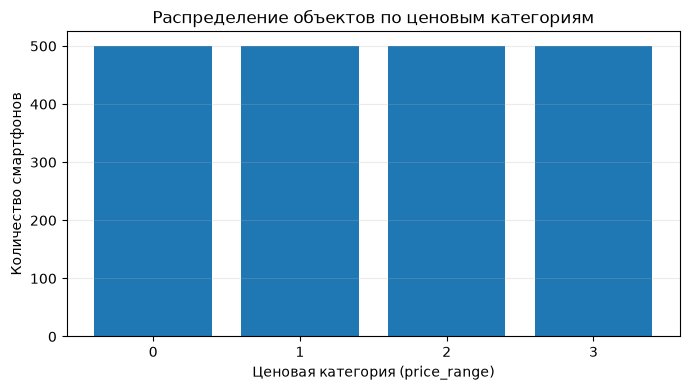

In [5]:
class_counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(class_counts.index.astype(str), class_counts.values)
ax.set_title("Распределение объектов по ценовым категориям")
ax.set_xlabel("Ценовая категория (price_range)")
ax.set_ylabel("Количество смартфонов")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Интерпретация распределения целевых классов

Столбчатая диаграмма показывает количество объектов в каждой ценовой категории. В исходном обучающем наборе классы сбалансированы: по 500 объектов на категорию. Это удобно для сравнения моделей. При разбиении данных будет дополнительно использован параметр `stratify`, чтобы сохранить пропорции классов в обучающей и тестовой выборках.

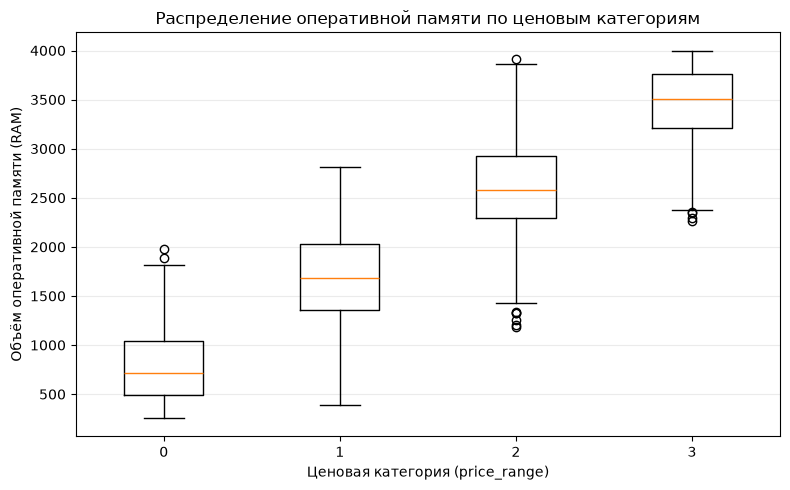

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
box_data = [df.loc[df[TARGET] == cls, "ram"].values for cls in sorted(df[TARGET].unique())]
ax.boxplot(box_data, tick_labels=[str(c) for c in sorted(df[TARGET].unique())])
ax.set_title("Распределение оперативной памяти по ценовым категориям")
ax.set_xlabel("Ценовая категория (price_range)")
ax.set_ylabel("Объём оперативной памяти (RAM)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Интерпретация распределения оперативной памяти

Диаграмма размаха позволяет сравнить распределение оперативной памяти в разных ценовых категориях. Если медианы и диапазоны заметно различаются, RAM может быть полезным признаком для классификации. При этом вывод нельзя делать только по одному признаку: модели будут использовать все 20 характеристик одновременно.

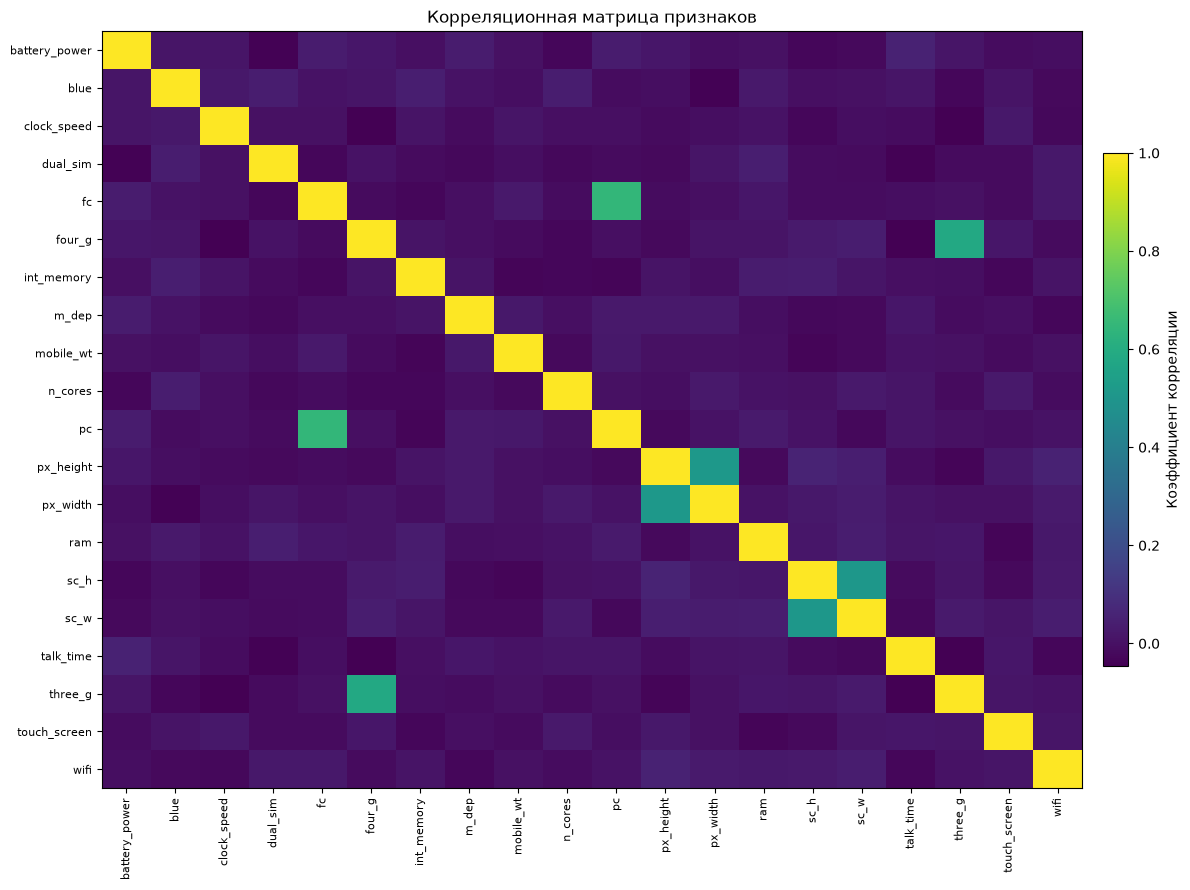

In [7]:
corr = df.drop(columns=[TARGET]).corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(12, 9))
image = ax.imshow(corr, aspect="auto", interpolation="nearest")
ax.set_title("Корреляционная матрица признаков")
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns, fontsize=8)
fig.colorbar(image, ax=ax, fraction=0.025, pad=0.02, label="Коэффициент корреляции")
plt.tight_layout()
plt.show()

### Интерпретация корреляционной матрицы

Корреляционная матрица показывает линейную связь между числовыми признаками. Сильно коррелирующие признаки могут содержать частично дублирующую информацию, однако удалять признаки только по этому графику не будем: цель работы — сравнить классификаторы на исходном наборе характеристик. Для LDA и других моделей влияние взаимосвязей будет отражаться в качестве на тестовой выборке.

In [8]:
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Размер X_train:", X_train.shape)
print("Размер X_test: ", X_test.shape)
print("Распределение классов в обучающей выборке:")
display(y_train.value_counts(normalize=True).sort_index().rename("Доля").to_frame())
print("Распределение классов в тестовой выборке:")
display(y_test.value_counts(normalize=True).sort_index().rename("Доля").to_frame())

Размер X_train: (1600, 20)
Размер X_test:  (400, 20)
Распределение классов в обучающей выборке:


,Доля
price_range,
0,0.25
1,0.25
2,0.25
3,0.25


Распределение классов в тестовой выборке:


,Доля
price_range,
0,0.25
1,0.25
2,0.25
3,0.25


### Результат разбиения на обучающую и тестовую выборки

Данные разделены в пропорции 80/20: 1600 объектов используются для обучения и подбора параметров, 400 — для итоговой оценки. Параметр `stratify=y` сохраняет доли четырёх классов в обеих выборках. Тестовая часть не используется при настройке гиперпараметров, поэтому она позволяет оценить обобщающую способность моделей на ранее не использованных объектах.

## 3. Методы классификации и схема эксперимента

В работе сравниваются восемь реализаций пяти семейств классификаторов:

1. **Наивный Байес:** GaussianNB, MultinomialNB, ComplementNB и BernoulliNB. GaussianNB моделирует распределения признаков внутри классов как нормальные; MultinomialNB и ComplementNB предназначены для неотрицательных признаков; BernoulliNB работает с бинарными признаками. Поэтому для BernoulliNB признаки будут преобразованы в два уровня, а для MultinomialNB и ComplementNB применится Min-Max масштабирование.
2. **Decision Tree:** строит последовательность правил и разделений признакового пространства.
3. **Linear Discriminant Analysis (LDA):** ищет линейные границы между классами при предположениях о распределениях признаков.
4. **Support Vector Machine (SVM):** строит разделяющую границу с максимальным зазором; проверяются линейное и RBF-ядро.
5. **k-Nearest Neighbors (k-NN):** относит объект к классу на основе ближайших объектов; признаки стандартизируются.

Для сравнения используются Accuracy, macro-Precision, macro-Recall, macro-F1 и ROC-AUC с подходом One-vs-Rest (OvR). Поскольку классов четыре, Precision, Recall и F1 рассчитываются как **macro average** — метрика считается отдельно для каждого класса, а затем классы усредняются с одинаковым весом. ROC-AUC рассчитывается как macro-average OvR.

Подбор гиперпараметров проводится через `GridSearchCV` с трёхкратной стратифицированной перекрёстной проверкой. Основной критерий выбора конфигурации — `F1_macro`. Все масштабирование и преобразование признаков находятся внутри `Pipeline`, поэтому в каждом фолде они подгоняются только по его обучающей части.

In [9]:
def make_model_pipelines():
    """Возвращает конвейеры восьми классификаторов."""
    return {
        "GaussianNB": Pipeline([
            ("scale", StandardScaler()),
            ("clf", GaussianNB())
        ]),
        "MultinomialNB": Pipeline([
            ("scale", MinMaxScaler()),
            ("clf", MultinomialNB())
        ]),
        "ComplementNB": Pipeline([
            ("scale", MinMaxScaler()),
            ("clf", ComplementNB())
        ]),
        "BernoulliNB": Pipeline([
            ("bin", KBinsDiscretizer(n_bins=2, encode="ordinal", strategy="uniform")),
            ("clf", BernoulliNB(binarize=0.5))
        ]),
        "Decision Tree": Pipeline([
            ("clf", DecisionTreeClassifier(random_state=SEED))
        ]),
        "LDA": Pipeline([
            ("scale", StandardScaler()),
            ("clf", LinearDiscriminantAnalysis())
        ]),
        "SVM": Pipeline([
            ("scale", StandardScaler()),
            ("clf", SVC(probability=True, random_state=SEED))
        ]),
        "k-NN": Pipeline([
            ("scale", StandardScaler()),
            ("clf", KNeighborsClassifier())
        ])
    }


def calculate_metrics(y_true, y_pred, y_prob):
    """Метрики многоклассовой классификации."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "ROC_AUC_macro_OvR": roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")
    }


def evaluate_model(model, X_eval, y_eval):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)
    return calculate_metrics(y_eval, pred, prob)

pipelines = make_model_pipelines()
print("Подготовлено моделей:", ", ".join(pipelines.keys()))

Подготовлено моделей: GaussianNB, MultinomialNB, ComplementNB, BernoulliNB, Decision Tree, LDA, SVM, k-NN


### Подготовка конвейеров классификаторов и метрик

Созданы конвейеры моделей и единая функция расчёта метрик. В каждом случае прогноз вероятностей берётся через `predict_proba`, что позволяет рассчитать ROC-AUC для четырёх классов. Для бинаризации BernoulliNB используется разбиение диапазона каждого признака на два интервала одинаковой ширины. Эти настройки не означают, что все алгоритмы обязаны использовать одинаковое преобразование: наоборот, конвейер учитывает требования конкретного метода.

In [10]:
# Базовые модели обучаются без поиска гиперпараметров.
baseline_models = {}
baseline_rows = []

for name, pipeline in pipelines.items():
    model = clone(pipeline)
    model.fit(X_train, y_train)
    baseline_models[name] = model
    row = {"Модель": name, **evaluate_model(model, X_test, y_test)}
    baseline_rows.append(row)

baseline_df = pd.DataFrame(baseline_rows).sort_values("F1_macro", ascending=False).reset_index(drop=True)
display(baseline_df.round(4))

c:\Users\petru\OneDrive\Рабочий стол\PHONE1\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Модель,Accuracy,Precision_macro,Recall_macro,F1_macro,ROC_AUC_macro_OvR
0,LDA,0.9550,0.9556,0.9550,0.9552,0.9958
1,SVM,0.8950,0.8969,0.8950,0.8956,0.9833
2,Decision Tree,0.8300,0.8319,0.8300,0.8302,0.8867
3,GaussianNB,0.8100,0.8113,0.8100,0.8105,0.9506
4,MultinomialNB,0.5975,0.6201,0.5975,0.6064,0.7969
5,BernoulliNB,0.5550,0.5432,0.5550,0.5460,0.8343
6,k-NN,0.5000,0.5211,0.5000,0.5054,0.7697
7,ComplementNB,0.5400,0.5461,0.5400,0.4493,0.7866


### Базовые результаты классификации

Таблица показывает исходное качество моделей с параметрами по умолчанию. Это отправная точка для исследования: далее будет проверено, улучшается ли качество после подбора гиперпараметров. Итоговые показатели рассчитаны только на тестовой выборке; данные этой выборки не использовались для обучения моделей.

In [11]:
param_grids = {
    "GaussianNB": {
        "clf__var_smoothing": [1e-11, 1e-9, 1e-7, 1e-5, 1e-3]
    },
    "MultinomialNB": {
        "clf__alpha": [0.01, 0.1, 1.0, 10.0]
    },
    "ComplementNB": {
        "clf__alpha": [0.01, 0.1, 1.0, 10.0],
        "clf__norm": [False, True]
    },
    "BernoulliNB": {
        "clf__alpha": [0.01, 0.1, 1.0, 10.0],
        "clf__fit_prior": [True, False]
    },
    "Decision Tree": {
        "clf__max_depth": [None, 4, 8, 12, 20],
        "clf__min_samples_leaf": [1, 2, 4],
        "clf__criterion": ["gini", "entropy"]
    },
    "LDA": [
        {"clf__solver": ["svd"]},
        {"clf__solver": ["lsqr"], "clf__shrinkage": [None, "auto", 0.1, 0.5]}
    ],
    "SVM": [
        {"clf__kernel": ["linear"], "clf__C": [0.1, 1, 10]},
        {"clf__kernel": ["rbf"], "clf__C": [0.1, 1, 10], "clf__gamma": ["scale", "auto"]}
    ],
    "k-NN": {
        "clf__n_neighbors": [3, 5, 7, 9, 11],
        "clf__weights": ["uniform", "distance"],
        "clf__p": [1, 2]
    }
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
searches = {}
tuned_models = {}
search_summary_rows = []

for name, pipeline in pipelines.items():
    print(f"Подбор параметров: {name}")
    search = GridSearchCV(
        estimator=clone(pipeline),
        param_grid=param_grids[name],
        scoring="f1_macro",
        cv=cv,
        n_jobs=1,
        refit=True,
        return_train_score=True,
        error_score="raise"
    )
    search.fit(X_train, y_train)
    searches[name] = search
    tuned_models[name] = search.best_estimator_
    clean_params = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    search_summary_rows.append({
        "Модель": name,
        "Лучший CV F1_macro": search.best_score_,
        "Лучшие параметры": str(clean_params)
    })

search_summary_df = pd.DataFrame(search_summary_rows).sort_values("Лучший CV F1_macro", ascending=False)
display(search_summary_df.round(4))

Подбор параметров: GaussianNB
Подбор параметров: MultinomialNB
Подбор параметров: ComplementNB
Подбор параметров: BernoulliNB
Подбор параметров: Decision Tree
Подбор параметров: LDA
Подбор параметров: SVM


c:\Users\petru\OneDrive\Рабочий стол\PHONE1\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\petru\OneDrive\Рабочий стол\PHONE1\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\petru\OneDrive\Рабочий стол\PHONE1\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\petru\OneDrive\Рабочий стол\PHONE1\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarn

Подбор параметров: k-NN


,Модель,Лучший CV F1_macro,Лучшие параметры
6,SVM,0.9625,"{'C': 10, 'kernel': 'linear'}"
5,LDA,0.9359,{'solver': 'svd'}
4,Decision Tree,0.8490,"{'criterion': 'entropy', 'max_depth': 8, 'min_..."
0,GaussianNB,0.7974,{'var_smoothing': 1e-11}
1,MultinomialNB,0.5889,{'alpha': 1.0}
7,k-NN,0.5649,"{'n_neighbors': 11, 'p': 1, 'weights': 'distan..."
3,BernoulliNB,0.5343,"{'alpha': 0.01, 'fit_prior': True}"
2,ComplementNB,0.4832,"{'alpha': 10.0, 'norm': True}"


### Результаты подбора гиперпараметров

Для каждой модели выполнен перебор заданных гиперпараметров с трёхкратной стратифицированной перекрёстной проверкой. Например, у дерева решений меняются глубина, критерий разделения и минимальное число объектов в листе; у SVM — ядро, `C` и `gamma`; у k-NN — число соседей, способ голосования и метрика расстояния. В таблице приведены параметры, которые дали наибольший средний macro-F1 на обучающей части. Тестовая выборка в подборе параметров не участвует.

In [12]:
# Для каждой модели показываем несколько лучших комбинаций параметров.
top_config_rows = []
for name, search in searches.items():
    cv_results = pd.DataFrame(search.cv_results_).sort_values("mean_test_score", ascending=False).head(3)
    for rank, (_, row) in enumerate(cv_results.iterrows(), start=1):
        params = {k.replace("clf__", ""): v for k, v in row["params"].items()}
        top_config_rows.append({
            "Модель": name,
            "Место в CV": rank,
            "Средний CV F1_macro": row["mean_test_score"],
            "Стандартное отклонение CV F1": row["std_test_score"],
            "Параметры": str(params)
        })

top_configs_df = pd.DataFrame(top_config_rows)
display(top_configs_df.round(4))

,Модель,Место в CV,Средний CV F1_macro,Стандартное отклонение CV F1,Параметры
0,GaussianNB,1,0.7974,0.0172,{'var_smoothing': 1e-11}
1,GaussianNB,2,0.7974,0.0172,{'var_smoothing': 1e-09}
2,GaussianNB,3,0.7974,0.0172,{'var_smoothing': 1e-07}
3,MultinomialNB,1,0.5889,0.0221,{'alpha': 1.0}
4,MultinomialNB,2,0.5888,0.0198,{'alpha': 0.01}
5,MultinomialNB,3,0.5888,0.0198,{'alpha': 0.1}
6,ComplementNB,1,0.4832,0.0187,"{'alpha': 10.0, 'norm': True}"
7,ComplementNB,2,0.4819,0.0180,"{'alpha': 0.01, 'norm': True}"
8,ComplementNB,3,0.4819,0.0180,"{'alpha': 0.1, 'norm': True}"
9,BernoulliNB,1,0.5343,0.0138,"{'alpha': 0.01, 'fit_prior': True}"


### Сравнение лучших конфигураций по перекрёстной проверке

Таблица позволяет увидеть не только победившую конфигурацию, но и несколько близких вариантов для каждого алгоритма. Если значения CV F1 у первых конфигураций почти одинаковы, небольшое изменение параметров не оказывает существенного влияния в рамках выбранного эксперимента. Если разница заметнее, настройка параметров влияет на разделение классов. Стандартное отклонение отражает изменчивость результата между фолдами.

In [13]:
# Сравниваем модели до и после настройки на одной и той же тестовой выборке.
tuned_rows = []
for name, model in tuned_models.items():
    tuned_rows.append({"Модель": name, **evaluate_model(model, X_test, y_test)})
tuned_df = pd.DataFrame(tuned_rows)

comparison_rows = []
for name in pipelines:
    b = baseline_df.loc[baseline_df["Модель"] == name].iloc[0]
    t = tuned_df.loc[tuned_df["Модель"] == name].iloc[0]
    for metric in ["Accuracy", "Precision_macro", "Recall_macro", "F1_macro", "ROC_AUC_macro_OvR"]:
        comparison_rows.append({
            "Модель": name,
            "Метрика": metric,
            "До настройки": b[metric],
            "После настройки": t[metric],
            "Изменение": t[metric] - b[metric]
        })

tuning_effect_df = pd.DataFrame(comparison_rows)
display(tuning_effect_df.round(4))

print("Лучшие настроенные модели по тестовому F1_macro:")
display(tuned_df.sort_values("F1_macro", ascending=False).reset_index(drop=True).round(4))

,Модель,Метрика,До настройки,После настройки,Изменение
0,GaussianNB,Accuracy,0.8100,0.8100,0.0000
1,GaussianNB,Precision_macro,0.8113,0.8113,0.0000
2,GaussianNB,Recall_macro,0.8100,0.8100,0.0000
3,GaussianNB,F1_macro,0.8105,0.8105,0.0000
4,GaussianNB,ROC_AUC_macro_OvR,0.9506,0.9506,0.0000
5,MultinomialNB,Accuracy,0.5975,0.5975,0.0000
6,MultinomialNB,Precision_macro,0.6201,0.6201,0.0000
7,MultinomialNB,Recall_macro,0.5975,0.5975,0.0000
8,MultinomialNB,F1_macro,0.6064,0.6064,0.0000
9,MultinomialNB,ROC_AUC_macro_OvR,0.7969,0.7969,0.0000


Лучшие настроенные модели по тестовому F1_macro:


,Модель,Accuracy,Precision_macro,Recall_macro,F1_macro,ROC_AUC_macro_OvR
0,SVM,0.9750,0.9750,0.9750,0.9750,0.9994
1,LDA,0.9550,0.9556,0.9550,0.9552,0.9958
2,Decision Tree,0.8825,0.8818,0.8825,0.8820,0.9485
3,GaussianNB,0.8100,0.8113,0.8100,0.8105,0.9506
4,k-NN,0.6175,0.6211,0.6175,0.6187,0.8335
5,MultinomialNB,0.5975,0.6201,0.5975,0.6064,0.7969
6,BernoulliNB,0.5550,0.5432,0.5550,0.5460,0.8344
7,ComplementNB,0.5700,0.5710,0.5700,0.5066,0.7818


### Влияние настройки гиперпараметров на метрики

Здесь показано фактическое изменение качества на тестовой выборке после подбора параметров. Положительное значение в столбце «Изменение» означает улучшение метрики, отрицательное — снижение. Улучшение на тесте не гарантируется: GridSearchCV выбирает параметры по перекрёстной проверке, а не по тестовой выборке. Сравнение помогает определить, какие модели выиграли от настройки, а какие уже работали близко к своему лучшему результату с параметрами по умолчанию.

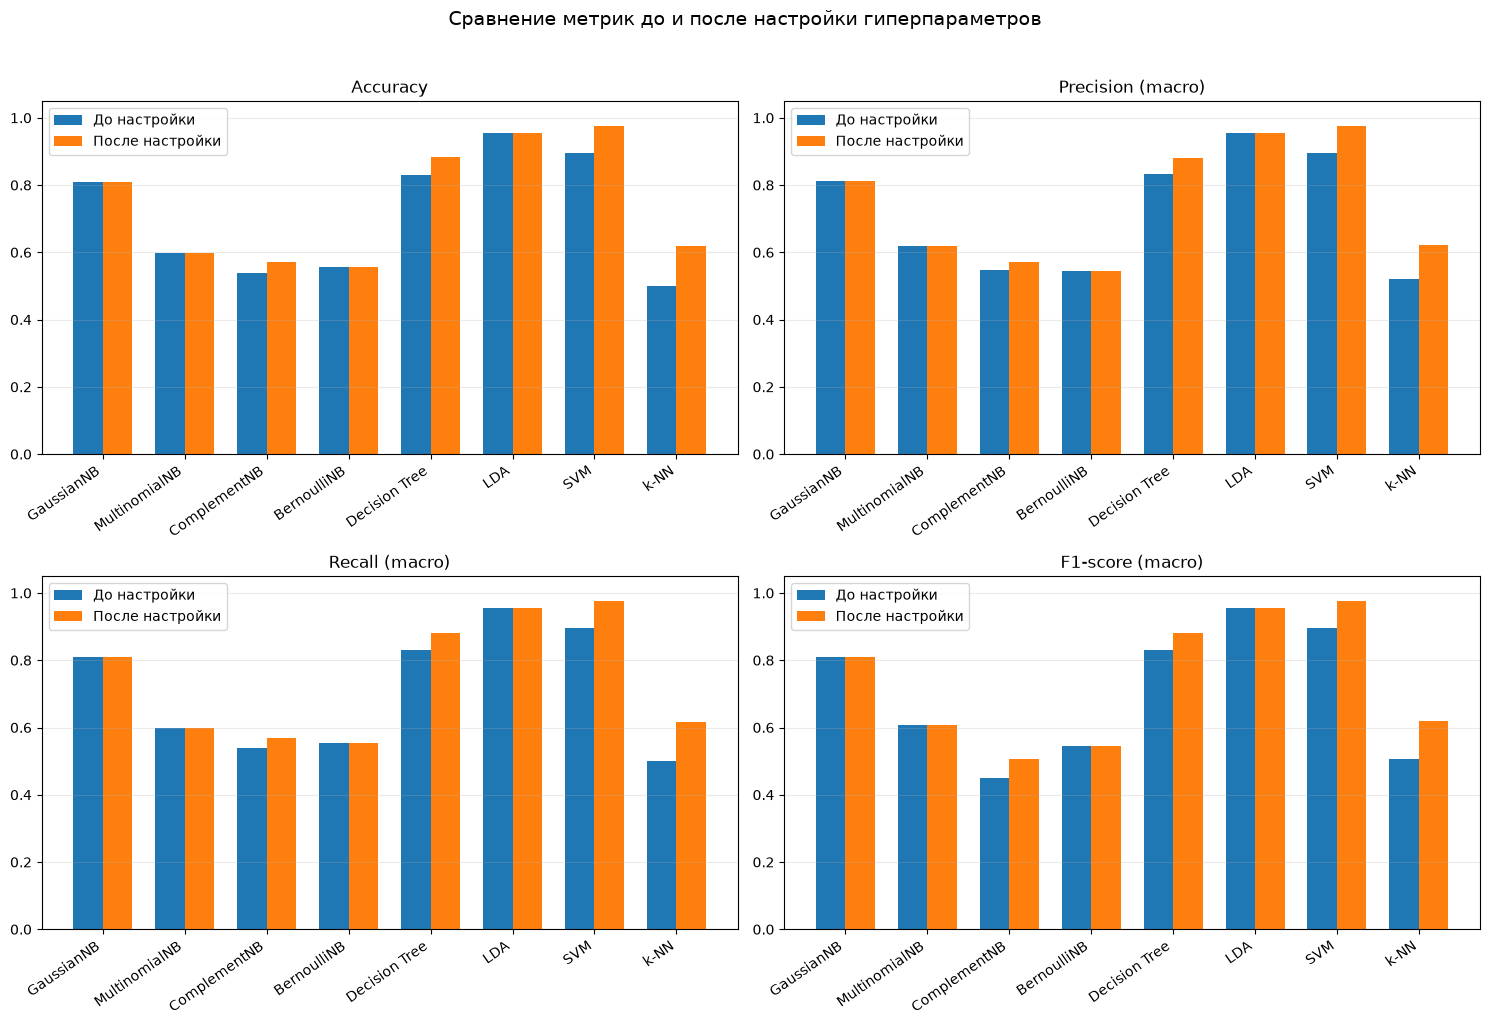

In [14]:
metrics_to_plot = [
    ("Accuracy", "Accuracy"),
    ("Precision_macro", "Precision (macro)"),
    ("Recall_macro", "Recall (macro)"),
    ("F1_macro", "F1-score (macro)")
]
model_order = list(pipelines.keys())
x = np.arange(len(model_order))
width = 0.36

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (metric, title) in zip(axes.ravel(), metrics_to_plot):
    base_values = [float(baseline_df.loc[baseline_df["Модель"] == name, metric].iloc[0]) for name in model_order]
    tuned_values = [float(tuned_df.loc[tuned_df["Модель"] == name, metric].iloc[0]) for name in model_order]
    ax.bar(x - width/2, base_values, width, label="До настройки")
    ax.bar(x + width/2, tuned_values, width, label="После настройки")
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=35, ha="right")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
fig.suptitle("Сравнение метрик до и после настройки гиперпараметров", y=1.02, fontsize=14)
fig.tight_layout()
plt.show()

### Сравнение метрик до и после настройки

На четырёх диаграммах сравниваются Accuracy, macro-Precision, macro-Recall и macro-F1 до и после настройки. Такое представление помогает быстро увидеть, где подбор параметров дал наибольший эффект. При выборе модели важно учитывать не только Accuracy: macro-F1 одинаково учитывает все четыре категории и объединяет Precision и Recall, а ROC-AUC отдельно характеризует качество ранжирования классов.

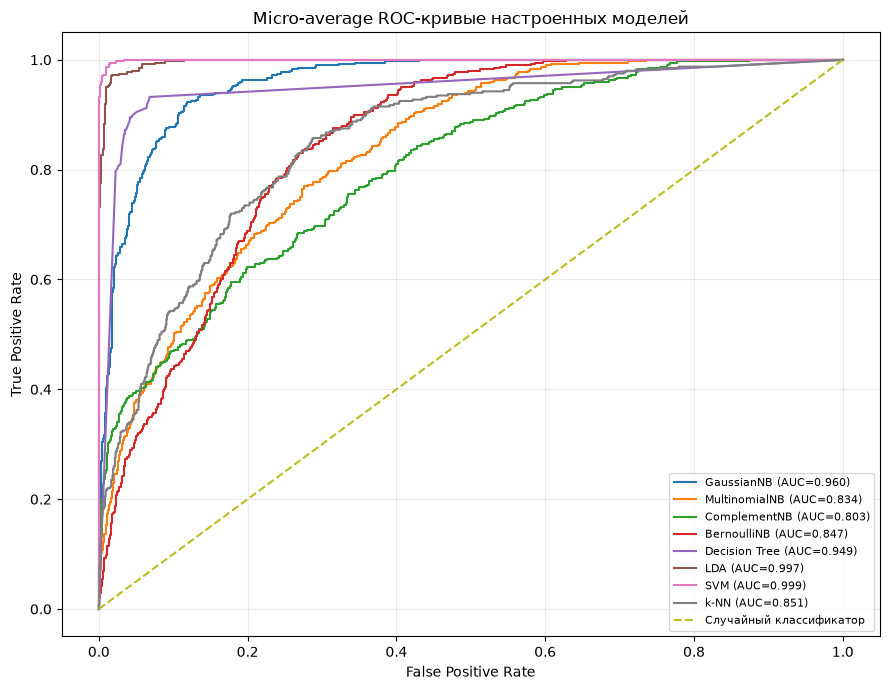

,Модель,Micro-average ROC-AUC
6,SVM,0.9995
5,LDA,0.9968
0,GaussianNB,0.9597
4,Decision Tree,0.9494
7,k-NN,0.8514
3,BernoulliNB,0.8472
1,MultinomialNB,0.8344
2,ComplementNB,0.8026


In [15]:
# Многоклассовые micro-average ROC-кривые для настроенных моделей.
class_labels = np.sort(y.unique())
y_test_bin = label_binarize(y_test, classes=class_labels)

fig, ax = plt.subplots(figsize=(9, 7))
roc_micro_rows = []
for name, model in tuned_models.items():
    prob = model.predict_proba(X_test)
    fpr, tpr, _ = roc_curve(y_test_bin.ravel(), prob.ravel())
    micro_auc = auc(fpr, tpr)
    roc_micro_rows.append({"Модель": name, "Micro-average ROC-AUC": micro_auc})
    ax.plot(fpr, tpr, label=f"{name} (AUC={micro_auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", label="Случайный классификатор")
ax.set_title("Micro-average ROC-кривые настроенных моделей")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.grid(alpha=0.25)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

display(pd.DataFrame(roc_micro_rows).sort_values("Micro-average ROC-AUC", ascending=False).round(4))

### Анализ ROC-кривых

ROC-кривые построены для многоклассовой задачи с объединением бинарных решений «один класс против остальных» в micro-average представление. Чем ближе кривая к левому верхнему углу, тем лучше модель отделяет классы при разных порогах. В таблице выше указана micro-average AUC для самих кривых. В основной сравнительной таблице используется macro-average OvR ROC-AUC; это другой способ усреднения, поэтому значения двух вариантов AUC могут отличаться.

**Лучшая классическая модель по тестовому F1_macro:** SVM.

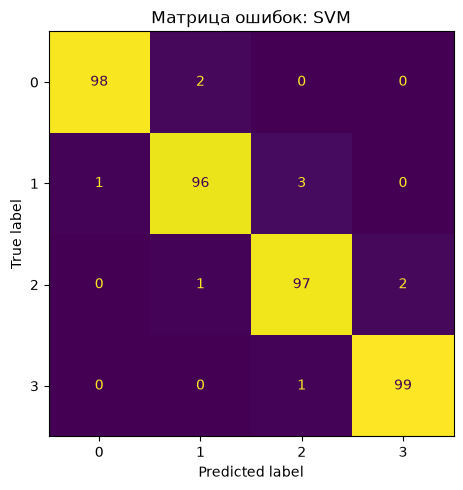

In [16]:
best_classic_name = tuned_df.sort_values("F1_macro", ascending=False).iloc[0]["Модель"]
best_classic_model = tuned_models[best_classic_name]
best_pred = best_classic_model.predict(X_test)
cm = confusion_matrix(y_test, best_pred, labels=class_labels)

display(Markdown(f"**Лучшая классическая модель по тестовому F1_macro:** {best_classic_name}."))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels).plot(ax=ax, values_format="d", colorbar=False)
ax.set_title(f"Матрица ошибок: {best_classic_name}")
plt.tight_layout()
plt.show()

### Анализ матрицы ошибок

Матрица ошибок показывает, сколько объектов каждого истинного класса модель отнесла к каждому предсказанному классу. Значения на главной диагонали соответствуют верным классификациям, а вне диагонали — ошибкам. Эта диаграмма дополняет агрегированные метрики и позволяет увидеть, какие ценовые категории модель чаще путает. Лучшая классическая модель на этом этапе выбрана по F1_macro на тестовой выборке; в отчёте это используется для описательного анализа, а не для повторной настройки параметров.

## 4. Нейронная сеть на TensorFlow/Keras

Для многоклассовой классификации используется полносвязная нейронная сеть. Входной слой получает 20 стандартизированных признаков, скрытые слои используют выбранную функцию активации (`relu` или `tanh`), а выходной слой содержит четыре нейрона с `softmax`. Функция потерь — `SparseCategoricalCrossentropy`, оптимизатор — Adam, метрика обучения — accuracy.

Для проверки обобщающей способности из обучающей части выделяется отдельная валидационная выборка. Тестовые данные не участвуют ни в обучении, ни в выборе архитектуры. Используется `EarlyStopping`, который останавливает обучение при отсутствии улучшения `val_loss` и восстанавливает лучшие веса. Для каждого эксперимента TensorBoard записывает ход обучения в отдельную папку `logs/fit/`.




In [17]:
nn_experiments = {}
nn_experiment_rows = []

if TF_AVAILABLE:
    from sklearn.preprocessing import StandardScaler

    # Отдельная валидационная часть выделяется только из обучающей выборки.
    X_nn_fit_raw, X_nn_val_raw, y_nn_fit, y_nn_val = train_test_split(
        X_train, y_train, test_size=0.20, random_state=SEED, stratify=y_train
    )
    nn_scaler = StandardScaler()
    X_nn_fit = nn_scaler.fit_transform(X_nn_fit_raw)
    X_nn_val = nn_scaler.transform(X_nn_val_raw)
    X_nn_test = nn_scaler.transform(X_test)

    def build_nn(hidden_units=(64, 32), activation="relu", learning_rate=0.001):
        layers = [tf.keras.layers.Input(shape=(X_nn_fit.shape[1],))]
        for units in hidden_units:
            layers.append(tf.keras.layers.Dense(units, activation=activation))
        layers.append(tf.keras.layers.Dense(4, activation="softmax"))
        model = tf.keras.Sequential(layers)
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )
        return model

    nn_configs = [
        {"name": "Базовая: 64-32, ReLU, 50 эпох, batch=32", "hidden_units": (64, 32), "activation": "relu", "epochs": 50, "batch_size": 32, "learning_rate": 0.001},
        {"name": "Меньше эпох: 64-32, ReLU, 20 эпох", "hidden_units": (64, 32), "activation": "relu", "epochs": 20, "batch_size": 32, "learning_rate": 0.001},
        {"name": "Batch=64: 64-32, ReLU", "hidden_units": (64, 32), "activation": "relu", "epochs": 50, "batch_size": 64, "learning_rate": 0.001},
        {"name": "Один слой: 32, ReLU", "hidden_units": (32,), "activation": "relu", "epochs": 50, "batch_size": 32, "learning_rate": 0.001},
        {"name": "Три слоя: 128-64-32, ReLU", "hidden_units": (128, 64, 32), "activation": "relu", "epochs": 50, "batch_size": 32, "learning_rate": 0.001},
        {"name": "Активация tanh: 64-32", "hidden_units": (64, 32), "activation": "tanh", "epochs": 50, "batch_size": 32, "learning_rate": 0.001}
    ]

    import tempfile

    # Создаем путь во временной директории Windows (вне OneDrive)
    log_root = Path(tempfile.gettempdir()) / "mobile_price_tf_logs"
    log_root.mkdir(parents=True, exist_ok=True)
    print(f"Логи TensorBoard будут сохранены в: {log_root}")

    for i, config in enumerate(nn_configs):
        tf.keras.utils.set_random_seed(SEED + i)
        model = build_nn(config["hidden_units"], config["activation"], config["learning_rate"])
        run_name = f"experiment_{i+1}"
        callbacks = [
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
            tf.keras.callbacks.TensorBoard(log_dir=str(log_root / run_name), update_freq="epoch")
        ]
        history = model.fit(
            X_nn_fit, y_nn_fit,
            validation_data=(X_nn_val, y_nn_val),
            epochs=config["epochs"],
            batch_size=config["batch_size"],
            callbacks=callbacks,
            verbose=0
        )
        val_prob = model.predict(X_nn_val, verbose=0)
        val_pred = np.argmax(val_prob, axis=1)
        row = {
            "Конфигурация": config["name"],
            "Скрытые слои": str(config["hidden_units"]),
            "Активация": config["activation"],
            "Запрошено эпох": config["epochs"],
            "Фактически эпох": len(history.history["loss"]),
            "Размер batch": config["batch_size"],
            "Validation accuracy": accuracy_score(y_nn_val, val_pred),
            "Validation F1_macro": f1_score(y_nn_val, val_pred, average="macro", zero_division=0)
        }
        nn_experiment_rows.append(row)
        nn_experiments[config["name"]] = {"model": model, "history": history, "config": config, "row": row}

    nn_experiment_df = pd.DataFrame(nn_experiment_rows).sort_values("Validation F1_macro", ascending=False).reset_index(drop=True)
    best_nn_name = nn_experiment_df.iloc[0]["Конфигурация"]
    best_nn_model = nn_experiments[best_nn_name]["model"]
    best_nn_history = nn_experiments[best_nn_name]["history"]
    best_nn_config = nn_experiments[best_nn_name]["config"]
    nn_available = True
    display(nn_experiment_df.round(4))
else:
    nn_available = False
    nn_scaler = None
    X_nn_test = None
    best_nn_name = None
    best_nn_model = None
    best_nn_history = None
    best_nn_config = None
    nn_experiment_df = pd.DataFrame()
    print("Нейросетевые эксперименты не запускались: TensorFlow отсутствует в текущей среде.")
    

Логи TensorBoard будут сохранены в: C:\Users\petru\AppData\Local\Temp\mobile_price_tf_logs


,Конфигурация,Скрытые слои,Активация,Запрошено эпох,Фактически эпох,Размер batch,Validation accuracy,Validation F1_macro
0,Активация tanh: 64-32,"(64, 32)",tanh,50,50,32,0.9750,0.9750
1,"Один слой: 32, ReLU","(32,)",relu,50,50,32,0.9312,0.9306
2,"Меньше эпох: 64-32, ReLU, 20 эпох","(64, 32)",relu,20,20,32,0.9250,0.9245
3,"Batch=64: 64-32, ReLU","(64, 32)",relu,50,50,64,0.9188,0.9184
4,"Три слоя: 128-64-32, ReLU","(128, 64, 32)",relu,50,16,32,0.9188,0.9174
5,"Базовая: 64-32, ReLU, 50 эпох, batch=32","(64, 32)",relu,50,36,32,0.9156,0.9151


### Результаты экспериментов с архитектурой нейронной сети

Проверены шесть конфигураций нейронной сети: базовая архитектура из двух скрытых слоёв, уменьшенное число эпох, другой размер batch, один скрытый слой, более глубокая сеть и функция активации `tanh`. Все варианты обучаются на одной и той же обучающей части и оцениваются на одной валидационной части. Конфигурация выбирается по `Validation F1_macro`, а не по тестовым данным. Если TensorFlow доступен, таблица фиксирует параметры и результат каждого эксперимента; иначе выводится явное предупреждение, чтобы не выдавать отсутствующие измерения за реальные.

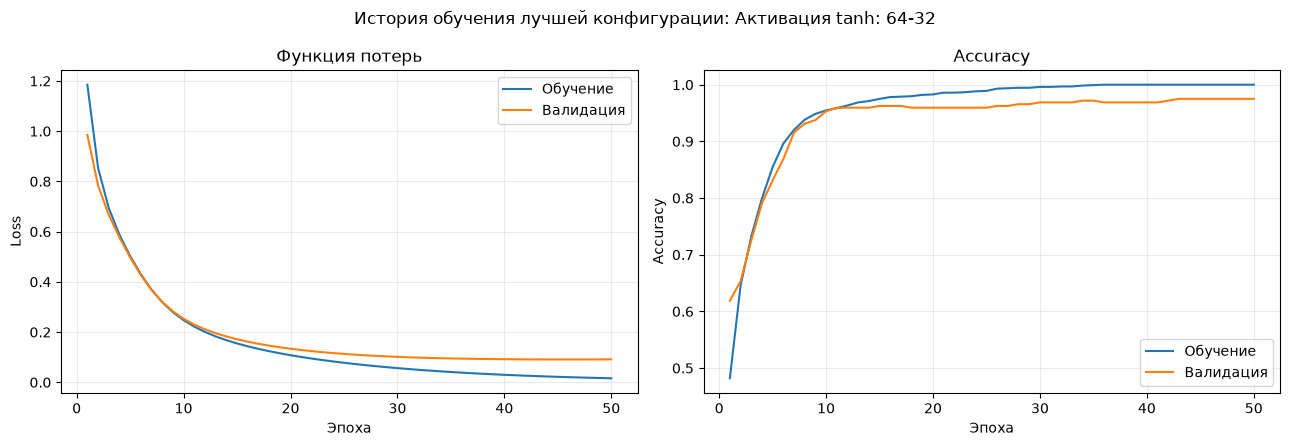

In [18]:
if nn_available:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    history = best_nn_history.history
    epochs_range = range(1, len(history["loss"]) + 1)

    axes[0].plot(epochs_range, history["loss"], label="Обучение")
    axes[0].plot(epochs_range, history["val_loss"], label="Валидация")
    axes[0].set_title("Функция потерь")
    axes[0].set_xlabel("Эпоха")
    axes[0].set_ylabel("Loss")
    axes[0].grid(alpha=0.25)
    axes[0].legend()

    axes[1].plot(epochs_range, history["accuracy"], label="Обучение")
    axes[1].plot(epochs_range, history["val_accuracy"], label="Валидация")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Эпоха")
    axes[1].set_ylabel("Accuracy")
    axes[1].grid(alpha=0.25)
    axes[1].legend()

    fig.suptitle(f"История обучения лучшей конфигурации: {best_nn_name}")
    fig.tight_layout()
    plt.show()
else:
    print("Графики обучения появятся после запуска нейросетевых экспериментов в среде с TensorFlow.")

### Анализ графиков обучения и валидации

Графики показывают изменение функции потерь и Accuracy на обучающей и валидационной выборках. Если обучение улучшается, а валидационная ошибка перестаёт снижаться или начинает расти, это может указывать на переобучение. `EarlyStopping` ограничивает этот эффект и возвращает веса с лучшим значением `val_loss`. Графики будут построены автоматически, когда нейросетевые эксперименты будут выполнены в среде с TensorFlow.

In [ ]:
if nn_available:
    # В Colab пытаемся открыть TensorBoard прямо в ноутбуке.
    try:
        import google.colab  # pyright: ignore[reportMissingImports]  # noqa: F401
        from IPython import get_ipython
        
        ip = get_ipython()
        if ip is not None:
            ip.run_line_magic("load_ext", "tensorboard")
            # Используем переменную log_root, которую мы настроили ранее
            ip.run_line_magic("tensorboard", f"--logdir {log_root}")
    except Exception as exc:
        print(f"Логи TensorBoard записаны в папку: {log_root}")
        print("Для просмотра запустите в отдельной ячейке Jupyter: %load_ext tensorboard")
        print(f"Затем выполните: %tensorboard --logdir {log_root}")
        print(f"Встроенный запуск в этой среде недоступен: {type(exc).__name__}: {exc}")
else:
    print("TensorBoard не запускался, поскольку TensorFlow не установлен.")

Логи TensorBoard записаны в папку: C:\Users\petru\AppData\Local\Temp\mobile_price_tf_logs
Для просмотра запустите в отдельной ячейке Jupyter: %load_ext tensorboard
Затем выполните: %tensorboard --logdir C:\Users\petru\AppData\Local\Temp\mobile_price_tf_logs
Встроенный запуск в этой среде недоступен: ModuleNotFoundError: No module named 'google.colab'


Журналы TensorBoard сохранены в: C:\Users\petru\AppData\Local\Temp\mobile_price_tf_logs

В терминале VS Code запустите команду ниже:

tensorboard --logdir "C:\Users\petru\AppData\Local\Temp\mobile_price_tf_logs"

Затем откройте URL, который появится в терминале (обычно http://localhost:6006).

python -m tensorboard.main --logdir "C:\Users\petru\AppData\Local\Temp\mobile_price_tf_logs" --port 6007

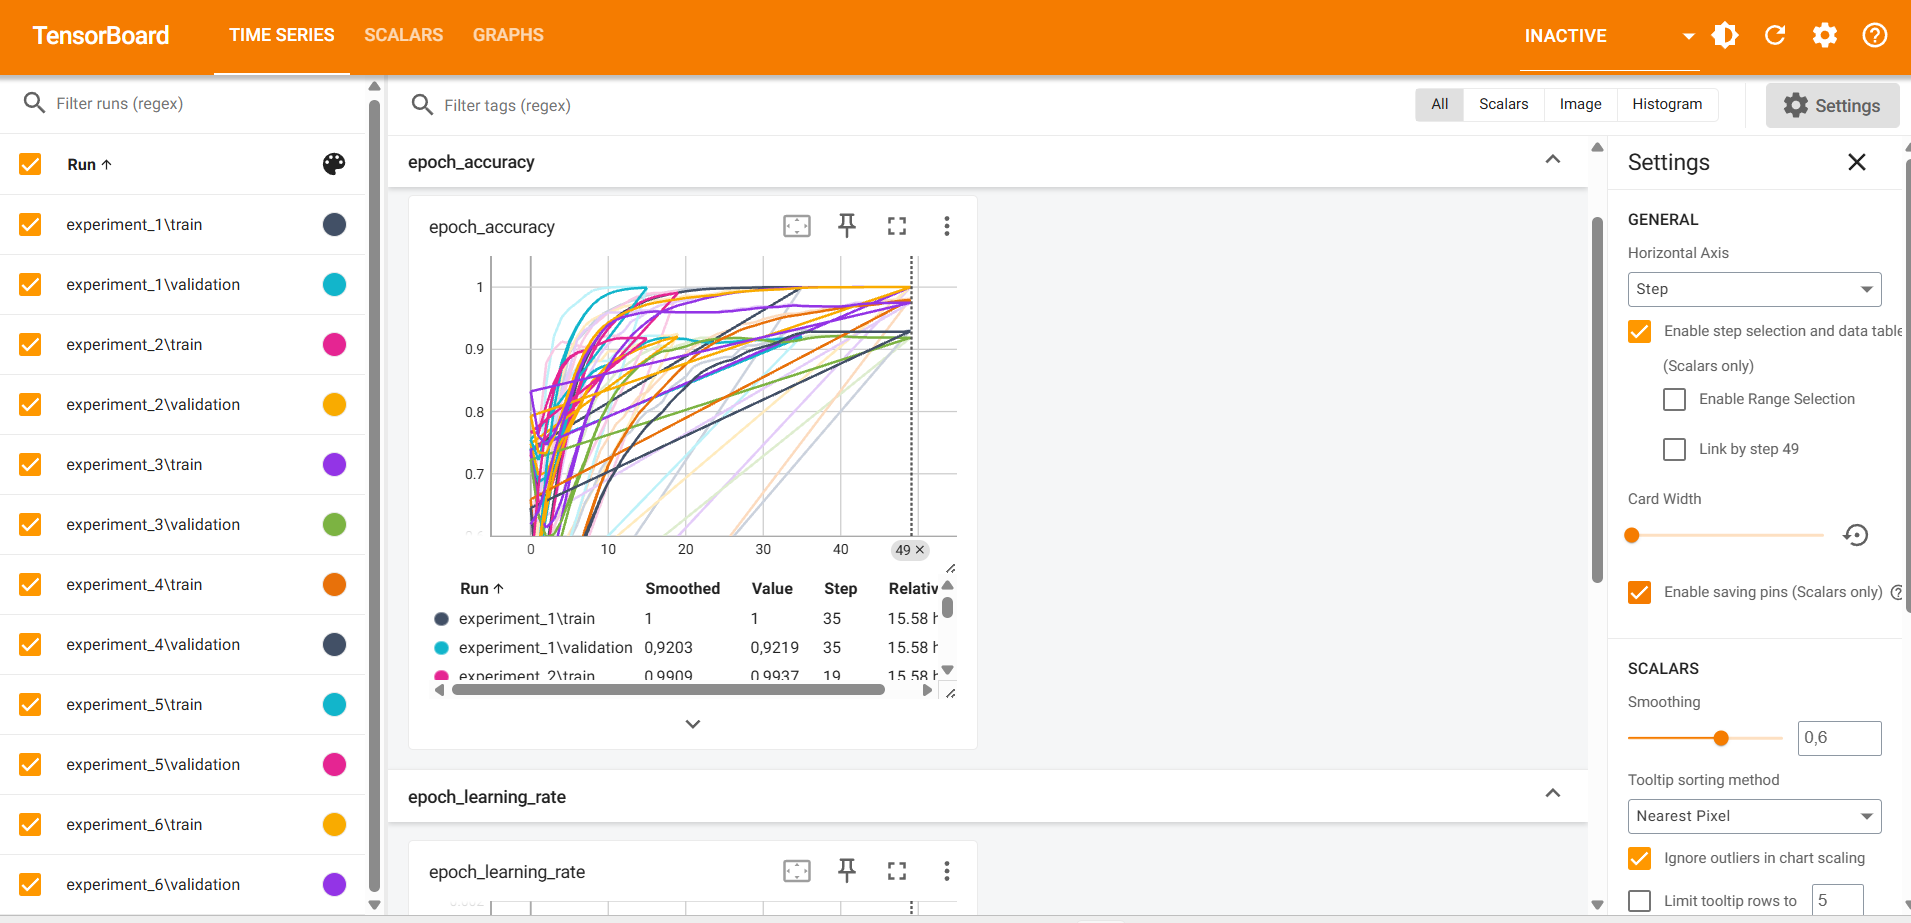

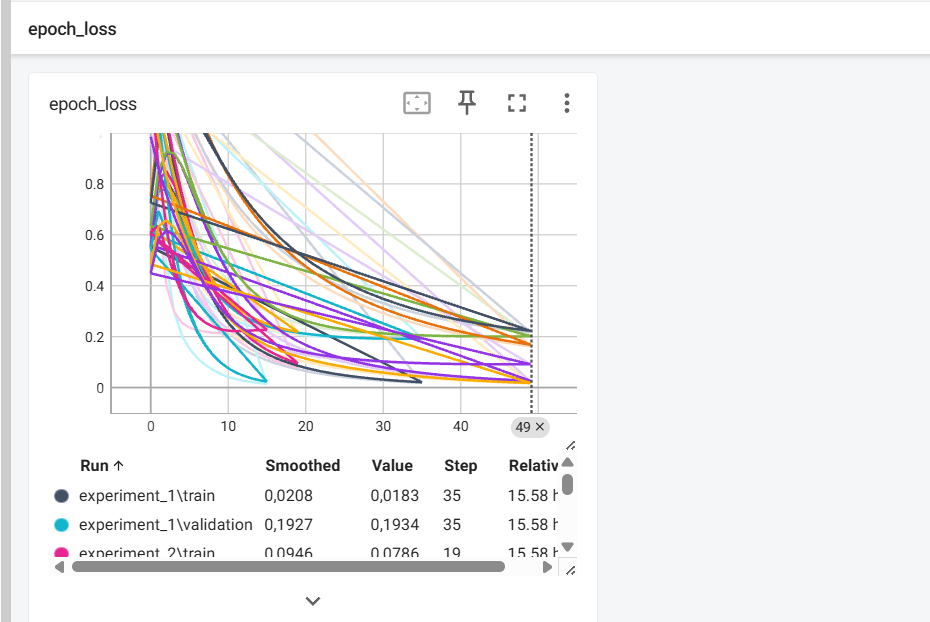

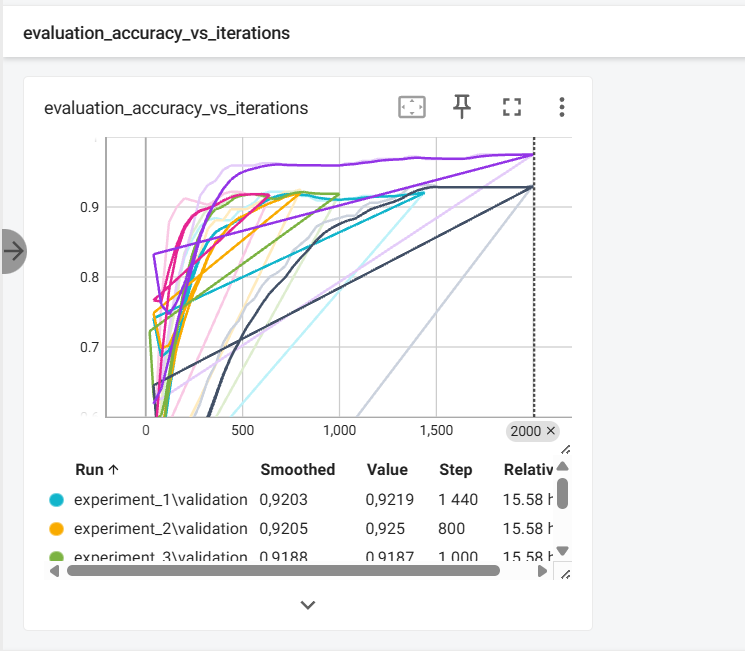

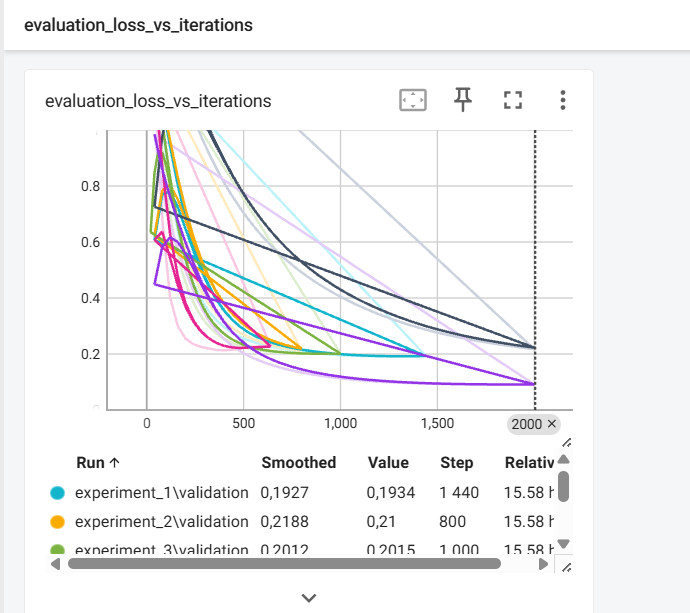

### Просмотр журналов TensorBoard в VS Code

Для каждой конфигурации callback `TensorBoard` сохраняет значения `loss`, `accuracy`, `val_loss` и `val_accuracy` в отдельной подпапке внутри каталога, путь к которому печатается в ячейке обучения . При необходимости выполните в отдельной ячейке магические команды `%load_ext tensorboard` и `%tensorboard --logdir "ПУТЬ_К_КАТАЛОГУ_ИЗ_ВЫВОДА"`. Альтернативно можно запустить TensorBoard из терминала и открыть указанный локальный адрес. Если TensorFlow отсутствовал во время обучения, журналов нет — они появятся после установки библиотек и повторного запуска нейросетевых экспериментов.


In [21]:
nn_test_metrics = None
nn_test_pred = None
nn_test_prob = None

if nn_available:
    nn_test_prob = best_nn_model.predict(X_nn_test, verbose=0)
    nn_test_pred = np.argmax(nn_test_prob, axis=1)
    nn_test_metrics = calculate_metrics(y_test, nn_test_pred, nn_test_prob)
    nn_test_row = {"Модель": "Neural Network (TensorFlow)", **nn_test_metrics}
    display(pd.DataFrame([nn_test_row]).round(4))
else:
    print("Тестовые метрики нейронной сети не рассчитаны: нет обученной TensorFlow-модели.")

,Модель,Accuracy,Precision_macro,Recall_macro,F1_macro,ROC_AUC_macro_OvR
0,Neural Network (TensorFlow),0.9475,0.9474,0.9475,0.9473,0.9978


### Оценка нейронной сети на тестовой выборке

После выбора конфигурации по валидационной F1-макро метрики нейронной сети рассчитываются на тестовой выборке, которая до этого момента не участвовала в выборе архитектуры. Результат сопоставим с классическими моделями, потому что используются те же тестовые объекты и те же функции расчёта метрик. Если TensorFlow не установлен, тестовые метрики нейросети намеренно не подменяются приблизительными значениями.

## 5. Сравнительный анализ результатов

В этом разделе итоговые версии классических классификаторов сравниваются с нейронной сетью по Accuracy, macro-Precision, macro-Recall, macro-F1 и ROC-AUC macro OvR. Все итоговые значения рассчитаны на одной и той же отложенной тестовой выборке. Если TensorFlow не установлен, для нейронной сети будут показаны пропуски, а не искусственно заданные значения.

In [22]:
# Итоговая таблица: лучшие настроенные классические модели и выбранная нейронная сеть (если она обучена).
final_rows = []
for name, model in tuned_models.items():
    final_rows.append({"Модель": name, **evaluate_model(model, X_test, y_test), "Статус": "Рассчитано"})

if nn_test_metrics is not None:
    final_rows.append({"Модель": "Neural Network (TensorFlow)", **nn_test_metrics, "Статус": "Рассчитано"})
else:
    final_rows.append({
        "Модель": "Neural Network (TensorFlow)",
        "Accuracy": np.nan,
        "Precision_macro": np.nan,
        "Recall_macro": np.nan,
        "F1_macro": np.nan,
        "ROC_AUC_macro_OvR": np.nan,
        "Статус": "Не рассчитано: TensorFlow отсутствует"
    })

final_comparison_df = pd.DataFrame(final_rows)
display(final_comparison_df.sort_values("F1_macro", ascending=False, na_position="last").reset_index(drop=True).round(4))

,Модель,Accuracy,Precision_macro,Recall_macro,F1_macro,ROC_AUC_macro_OvR,Статус
0,SVM,0.9750,0.9750,0.9750,0.9750,0.9994,Рассчитано
1,LDA,0.9550,0.9556,0.9550,0.9552,0.9958,Рассчитано
2,Neural Network (TensorFlow),0.9475,0.9474,0.9475,0.9473,0.9978,Рассчитано
3,Decision Tree,0.8825,0.8818,0.8825,0.8820,0.9485,Рассчитано
4,GaussianNB,0.8100,0.8113,0.8100,0.8105,0.9506,Рассчитано
5,k-NN,0.6175,0.6211,0.6175,0.6187,0.8335,Рассчитано
6,MultinomialNB,0.5975,0.6201,0.5975,0.6064,0.7969,Рассчитано
7,BernoulliNB,0.5550,0.5432,0.5550,0.5460,0.8344,Рассчитано
8,ComplementNB,0.5700,0.5710,0.5700,0.5066,0.7818,Рассчитано


### Сводная таблица качества всех моделей

Это итоговая таблица для отчёта: в ней представлены лучшие настроенные версии восьми классических классификаторов и нейронная сеть TensorFlow. Все рассчитанные значения получены на одной тестовой выборке. Если в строке нейронной сети стоят пропуски, значит, TensorFlow не был доступен при выполнении соответствующих ячеек. Такие значения нельзя интерпретировать как нулевое качество модели: сначала установите зависимости и повторно выполните ноутбук сверху вниз.


In [23]:
# Формируем итоговый вывод на основе фактически рассчитанных тестовых метрик.
valid_results = final_comparison_df.dropna(subset=["F1_macro"]).copy()
if not valid_results.empty:
    winner = valid_results.sort_values("F1_macro", ascending=False).iloc[0]
    best_auc_row = valid_results.sort_values("ROC_AUC_macro_OvR", ascending=False).iloc[0]
    tf_note = (
        "Нейронная сеть TensorFlow включена в сравнение."
        if nn_test_metrics is not None
        else "Нейросетевая часть подготовлена, но не рассчитана в текущей среде из-за отсутствия TensorFlow; для полного сравнения установите tensorflow и tensorboard в выбранное окружение и повторно выполните ноутбук."
    )
    conclusion = f"""### Итог по результатам эксперимента

По тестовой метрике **F1_macro** лучший результат среди рассчитанных моделей показала **{winner["Модель"]}** (F1_macro = **{winner["F1_macro"]:.4f}**, Accuracy = **{winner["Accuracy"]:.4f}**, ROC-AUC macro OvR = **{winner["ROC_AUC_macro_OvR"]:.4f}**). Это означает, что среди моделей с рассчитанными метриками она обеспечила наиболее высокий средний F1 по четырём ценовым категориям.

Наибольший **ROC-AUC macro OvR** показала модель **{best_auc_row["Модель"]}** ({best_auc_row["ROC_AUC_macro_OvR"]:.4f}). Лучший F1 и лучший AUC могут принадлежать разным моделям: первая метрика оценивает качество конечных классовых предсказаний, а вторая — способность ранжировать классы при изменении порогов.

{tf_note}

Результат следует рассматривать в рамках данного набора данных и выбранного разбиения. Для учебной задачи модель выбирается по совокупности метрик, а не только по Accuracy."""
    display(Markdown(conclusion))
else:
    print("Нет рассчитанных метрик для итогового вывода.")

### Итог по результатам эксперимента

По тестовой метрике **F1_macro** лучший результат среди рассчитанных моделей показала **SVM** (F1_macro = **0.9750**, Accuracy = **0.9750**, ROC-AUC macro OvR = **0.9994**). Это означает, что среди моделей с рассчитанными метриками она обеспечила наиболее высокий средний F1 по четырём ценовым категориям.

Наибольший **ROC-AUC macro OvR** показала модель **SVM** (0.9994). Лучший F1 и лучший AUC могут принадлежать разным моделям: первая метрика оценивает качество конечных классовых предсказаний, а вторая — способность ранжировать классы при изменении порогов.

Нейронная сеть TensorFlow включена в сравнение.

Результат следует рассматривать в рамках данного набора данных и выбранного разбиения. Для учебной задачи модель выбирается по совокупности метрик, а не только по Accuracy.

### Интерпретация итогового сравнения

Заключение формируется автоматически из фактически полученных метрик, поэтому в нём не используются выдуманные значения. При оценке учитываются две стороны качества: F1_macro характеризует баланс Precision и Recall по всем классам, а ROC-AUC macro OvR — способность модели разделять каждый класс относительно остальных. Если нейронная сеть не обучена из-за отсутствия TensorFlow, вывод прямо указывает на это ограничение.

## 6. Заключение

В ходе лабораторной работы подготовлен датасет Mobile Price Classification и выполнено стратифицированное разделение данных на обучающую и тестовую выборки. Реализованы четыре варианта наивного Байесовского классификатора, дерево решений, линейный дискриминантный анализ, метод опорных векторов и метод ближайших соседей. Для моделей выполнен подбор гиперпараметров с использованием перекрёстной проверки, а качество до и после настройки сопоставлено на одинаковой тестовой выборке.

Качество оценивалось по Accuracy, macro-Precision, macro-Recall, macro-F1 и ROC-AUC macro OvR. Построены графики распределения классов, исследовательские диаграммы, сравнительные столбчатые графики, ROC-кривые и матрица ошибок. В нейросетевой части предусмотрены сравнение архитектур, функций активации, количества эпох и размера batch, построение графиков обучения и валидации, а также журналирование TensorBoard.

При интерпретации результатов следует учитывать, что `price_range` — это четыре категории из учебного датасета, а не реальные цены смартфонов. Итоговая модель подходит для демонстрации методов классификации на данном наборе данных; результаты не следует автоматически переносить на актуальные модели телефонов или реальные рыночные цены.


